<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/Walmart%20Midterm%20Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Salt Squared Midterm Submission**
##**Group Members:**
### Noor Imat, Angela Benedict, Aubin Barcheck, and Nico Roppatte

# Cleaning

In [23]:
import pandas as pd
import string

BASE = "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/main/notebooks/walmart-hurricane-project/data/"

# decision log (from the Sept 23 Cleaning Clinic studio)
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({"step": step, "decision": decision, "rows": int(rows_affected)})
    print(f"[{step}] {decision} ({rows_affected} row(s))")

def show_log():
    return pd.DataFrame(DECISIONS)

CATEGORY_MAP = {
    "emergency": "Emergency Supplies", "emergency supplies": "Emergency Supplies",
    "groceries": "Groceries", "grocery": "Groceries",
    "electronics": "Electronics",
    "household": "Household", "household essentials": "Household",
    "baby": "Baby Products", "baby products": "Baby Products",
    "breakfast": "Breakfast Foods", "breakfast foods": "Breakfast Foods",
    "health": "Health", "health & wellness": "Health",
    "alcohol": "Alcohol", "alcoholic beverages": "Alcohol",
    "games & entertainment": "Entertainment", "entertainment": "Entertainment",
    "snacks": "Snacks",
}

def clean_category(col):
    return col.astype(str).str.strip().str.lower().map(CATEGORY_MAP)

def clean_store_id(col):
    return (col.astype(str).str.strip().str.upper()
               .str.replace("_", "-", regex=False)
               .str.replace(r"^FL(\d+)$", r"FL-\1", regex=True))

def normalize_product_name(name):
    if pd.isna(name):
        return None
    words = name.lower().translate(str.maketrans("", "", string.punctuation)).split()
    return " ".join(sorted(words))


# 1. product catalog
def clean_products(products):
    before = len(products)
    products = products.dropna(subset=["product_name", "sku"]).copy()
    log("product names", "dropped products with no name or SKU", before - len(products))

    products["normalized_name"] = products["product_name"].apply(normalize_product_name)
    log("normalize product names", "lowercased, removed punctuation, sorted words",
        (products["product_name"] != products["normalized_name"]).sum())

    old = products["category"].copy()
    products["category"] = clean_category(products["category"])
    log("product categories", "stripped spaces, lowercased, mapped spelling variants to 10 categories",
        (old != products["category"]).sum())

    old = products["package_size"].copy()
    products["package_size"] = (products["package_size"].str.strip().str.lower()
                                .str.replace(r"(\d+)\s*(pk|pack|-pack)$", r"\1-pack", regex=True))
    log("package size", "lowercased, stripped spaces, standardized to '#-pack'",
        (old != products["package_size"]).sum())
    return products


# 2. store locations
def clean_stores(stores):
    stores = stores.copy()
    old = stores["state"].copy()
    stores["state"] = (stores["state"].str.strip().str.upper()
                       .str.replace(r"[^\w\s]", "", regex=True)
                       .replace({"FLORIDA": "FL", "FLA": "FL"}))
    log("store state", "removed punctuation, uppercased, changed 'Florida' and 'Fla.' to 'FL'",
        (old != stores["state"]).sum())

    old = stores["store_id"].copy()
    stores["store_id"] = clean_store_id(stores["store_id"])
    log("store location IDs", "uppercased, replaced _ with -, added missing dashes (FL239 -> FL-239)",
        (old != stores["store_id"]).sum())

    before = len(stores)
    stores = stores.drop_duplicates(subset="store_id")
    log("duplicate stores", "dropped repeated stores after fixing IDs", before - len(stores))
    return stores


# 3. sales transactions
def clean_sales(sales):
    before = len(sales)
    sales = sales.drop_duplicates().copy()
    log("sales duplicates", "dropped exact duplicate rows", before - len(sales))

    old = sales["store_id"].copy()
    sales["store_id"] = clean_store_id(sales["store_id"])
    log("sales store IDs", "uppercased, replaced _ with -, added missing dashes so IDs match the store file",
        (old != sales["store_id"]).sum())

    had_dollar = sales["unit_price"].astype(str).str.contains("$", regex=False).sum()
    sales["unit_price"] = pd.to_numeric(sales["unit_price"].astype(str).str.replace("$", "", regex=False).str.strip(),
                                        errors="coerce")
    log("unit price", f"removed $ from {had_dollar} prices and converted the column to numbers", len(sales))

    blank =sales["timestamp"].isna().sum()
    log("missing timestamps", "kept rows with blank timestamps; they are skipped in anything by date", blank)
    sales["timestamp"] = pd.to_datetime(sales["timestamp"], format="mixed", errors="coerce")
    sales["date"] = sales["timestamp"].dt.normalize()
    log("convert timestamps", "parsed 5 different date formats to datetime with format='mixed'",
        sales["timestamp"].notna().sum())

    sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce")
    log("negative quantities", "kept as returns (under 1% of units)", (sales["quantity"] < 0).sum())

    old = sales["category"].copy()
    sales["category_clean"] = clean_category(sales["category"])
    log("sales categories", "stripped spaces, lowercased, mapped spelling variants to 10 categories",
        (old != sales["category_clean"]).sum())

    # SKU consolidation: SKUs sold under the same product name are the same product
    sales["name_clean"] = sales["product_name"].astype(str).str.strip().str.lower()
    parent = {sku: sku for sku in sales["sku"].unique()}
    def find(sku):
        while parent[sku] != sku:
            sku = parent[sku]
        return sku
    for name, skus in sales.groupby("name_clean")["sku"].unique().items():
        for sku in skus[1:]:
            parent[find(sku)] = find(skus[0])
    sales["sku_canonical"] = sales["sku"].map(find)
    skus_before = sales["sku"].nunique()
    log("SKU consolidation", f"merged SKUs that share a product name: {skus_before} SKUs -> "
        f"{sales['sku_canonical'].nunique()} products (details in Q2)",
        skus_before - sales["sku_canonical"].nunique())
    return sales


# run the whole pipeline top to bottom
products_clean = clean_products(pd.read_csv(BASE + "product_catalog.csv"))
stores_clean = clean_stores(pd.read_csv(BASE + "store_locations.csv"))
sales_clean = clean_sales(pd.read_csv(BASE + "walmart_transactions.csv"))

print("\nrows after cleaning:", len(sales_clean))
show_log()

[product names] dropped products with no name or SKU (0 row(s))
[normalize product names] lowercased, removed punctuation, sorted words (45 row(s))
[product categories] stripped spaces, lowercased, mapped spelling variants to 10 categories (36 row(s))
[package size] lowercased, stripped spaces, standardized to '#-pack' (26 row(s))
[store state] removed punctuation, uppercased, changed 'Florida' and 'Fla.' to 'FL' (4 row(s))
[store location IDs] uppercased, replaced _ with -, added missing dashes (FL239 -> FL-239) (2 row(s))
[duplicate stores] dropped repeated stores after fixing IDs (2 row(s))
[sales duplicates] dropped exact duplicate rows (30 row(s))
[sales store IDs] uppercased, replaced _ with -, added missing dashes so IDs match the store file (4345 row(s))
[unit price] removed $ from 3026 prices and converted the column to numbers (25532 row(s))
[missing timestamps] kept rows with blank timestamps; they are skipped in anything by date (884 row(s))
[convert timestamps] parsed 5 di

,step,decision,rows
0,product names,dropped products with no name or SKU,0
1,normalize product names,"lowercased, removed punctuation, sorted words",45
2,product categories,"stripped spaces, lowercased, mapped spelling v...",36
3,package size,"lowercased, stripped spaces, standardized to '...",26
4,store state,"removed punctuation, uppercased, changed 'Flor...",4
5,store location IDs,"uppercased, replaced _ with -, added missing d...",2
6,duplicate stores,dropped repeated stores after fixing IDs,2
7,sales duplicates,dropped exact duplicate rows,30
8,sales store IDs,"uppercased, replaced _ with -, added missing d...",4345
9,unit price,removed $ from 3026 prices and converted the c...,25532


**Decision Log**

The table above is our decision log: each cleaning step, what we did, and how many rows it affected.

# Weather Join

Source: Open-Meteo Historical Weather API, https://archive-api.open-meteo.com/v1/archive (Orlando, Sept 2024).

In [24]:
import pandas as pd
import numpy as np
import requests
import time

transactions = pd.read_csv(
    "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/refs/heads/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)

# messy timestamp formats before cleaning
formats = transactions["timestamp"].fillna("MISSING").str.replace(r"\d", "9", regex=True)
display(formats.value_counts())

def prepare_sales_for_weather_join(sales_df, timestamp_col):
    sales = sales_df.copy()

    before = len(sales)
    sales = sales.drop_duplicates()
    print("Duplicate rows removed:", before - len(sales))

    sales[timestamp_col] = pd.to_datetime(sales[timestamp_col], format="mixed", errors="coerce")
    sales["date"] = sales[timestamp_col].dt.normalize()

    print("Rows:", len(sales))
    print("Missing dates:", sales["date"].isna().sum())
    return sales

sales_prepared = prepare_sales_for_weather_join(transactions, "timestamp")

daily_sales = (
    sales_prepared
    .dropna(subset=["date"])
    .groupby("date")
    .size()
    .reset_index(name="orders")
)
print("Days of sales:", len(daily_sales))

BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": "precipitation_sum,windspeed_10m_max",
        "hourly": "surface_pressure",
        "timezone": "America/New_York",
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=30)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        data = r.json()

        frame = pd.DataFrame(data["daily"]).rename(columns={"time": "date"})
        frame["date"] = pd.to_datetime(frame["date"])

        # hourly pressure -> daily mean
        pressure = pd.DataFrame(data["hourly"])
        pressure["date"] = pd.to_datetime(pressure["time"]).dt.normalize()
        daily_pressure = (
            pressure.groupby("date", as_index=False)["surface_pressure"].mean()
            .rename(columns={"surface_pressure": "surface_pressure_mean"})
        )
        frame = frame.merge(daily_pressure, on="date", how="left")
        frame["source"] = "open-meteo"
        return frame

weather_live = daily_weather("2024-09-01", "2024-09-30")
print("source:", weather_live["source"].iloc[0])

# timezone check: UTC days vs Eastern days
params = {
    "latitude": 28.54, "longitude": -81.38,
    "start_date": "2024-09-01", "end_date": "2024-09-30",
    "hourly": "windspeed_10m",
    "timezone": "GMT",
}
r = requests.get(BASE, params=params, timeout=30)
r.raise_for_status()
hourly = pd.DataFrame(r.json()["hourly"])
hourly["time_utc"] = pd.to_datetime(hourly["time"]).dt.tz_localize("UTC")
hourly["time_et"] = hourly["time_utc"].dt.tz_convert("America/New_York")
hourly["date_utc"] = hourly["time_utc"].dt.tz_localize(None).dt.normalize()
hourly["date_et"] = hourly["time_et"].dt.tz_localize(None).dt.normalize()
print("Hours that fall on a different date in UTC vs Eastern:",
      (hourly["date_utc"] != hourly["date_et"]).sum(), "of", len(hourly))
compare = pd.DataFrame({
    "max wind, UTC days": hourly.groupby("date_utc")["windspeed_10m"].max(),
    "max wind, Eastern days": hourly.groupby("date_et")["windspeed_10m"].max(),
}).loc["2024-09-24":"2024-09-28"]
display(compare)

# validated left join
sales_weather = daily_sales.merge(weather_live, on="date", how="left")
print("Sales rows before join:", len(daily_sales))
print("Rows after join:", len(sales_weather))
print("Missing weather rows:", sales_weather["precipitation_sum"].isna().sum())
assert len(sales_weather) == len(daily_sales), "join changed the row count"
assert sales_weather["orders"].sum() == daily_sales["orders"].sum(), "join changed total orders"
print("All join checks passed")

weather_live.to_csv("weather_orlando_sept2024.csv", index=False)
sales_weather.to_csv("sales_weather_daily.csv", index=False)

,count
timestamp,
9999-99-99 99:99:99,12179
99/99/9999 99:99,5031
99-Sep-9999 99:99,2546
9999-99-99T99:99:99,2511
99-99-9999 99:99:99,2409
MISSING,886


Duplicate rows removed: 30
Rows: 25532
Missing dates: 884
Days of sales: 30
source: open-meteo
Hours that fall on a different date in UTC vs Eastern: 120 of 720


,"max wind, UTC days","max wind, Eastern days"
2024-09-24,17.7,17.7
2024-09-25,27.2,27.2
2024-09-26,46.1,48.8
2024-09-27,48.8,45.1
2024-09-28,19.8,19.8


Sales rows before join: 30
Rows after join: 30
Missing weather rows: 0
All join checks passed


**Timezone handling:** Open-Meteo uses UTC as its default timezone, while the sales data is in Eastern time (UTC-4 in September). In UTC, the last four hours of each Eastern day belong to the next day, and therefore, 120 out of 720 hours have the wrong date. In order to avoid this problem, the weather API request has been made by setting timezone=America/New_York, making each day the same midnight to midnight as that of the sales data. Without the timezone conversion, the highest wind speed (48.8 km/h) would occur on September 27 instead of September 26, the day of landfall.

# Questions and Visualizations

## **Question 1:**

**Markdown Explanation of What We Did**

**Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.**

## **Question 2:**

In [25]:
import pandas as pd
#uploading data
url = "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv" #where we are pulling data from
sales = pd.read_csv(url).drop_duplicates() #reading the url files for our sales and dropping duplicates
sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce") #making quantity a numeric value

#Cleaning names
sales["name_clean"] = sales["product_name"].str.lower().str.replace(r'[^a-z ]', ' ', regex=True).str.split().apply(lambda w: ' '.join(sorted(w))) #lowercase, strip punctuation, and sorted the words

#Starting number of unique values
print("Distinct SKUs before:", sales["sku"].nunique()) #seeing how many distinct skus we have at the start
print("Distinct product names before:", sales["product_name"].nunique()) #seeing how many distinct product names we start with

#Seeing where skus overlap for the same product
sku_check = sales.groupby("name_clean")["sku"].unique().loc[lambda s: s.str.len()>1] #grouped by the normalization from above, and then the len>1 puts the groups holding more than one SKU
display(sku_check)

#creating mapping table so that skus under the same product are consolidated
sku_mapping = pd.DataFrame({'raw_sku':['PT-12',
                                       'SKU#459812',
                                       'POPTART-STRAW',
                                       'PT_STRAWBERRY',
                                       'WTR-24',
                                       'WATER24PK',
                                       'WTR_24PK',
                                       'BATT-100',
                                       'BAT-AA4',
                                       'BATT_AA_4PK',
                                       'FLASH-01',
                                       'LED-FLASH',
                                       'BEER-24',
                                       'LTBEER24',
                                       'BG-MONO',
                                       'MONOPOLY-01',
                                       'GAME-MONO',
                                       'CARDS-01',
                                       'PLAYCARD-STD',
                                       'STREAM-01',
                                       'ROKU-STD',
                                       'SOUP-CAN',
                                       'CNSOUP-01',
                                       'BREAD-WH',
                                       'WHITEBREAD',
                                       'PB-16',
                                       'PNUTBTR-16',
                                       'CNDL-EM',
                                       'CANDLE-EMRG',
                                       'FAID-01',
                                       'FIRSTAID-KIT',
                                       'CHRG-PORT',
                                       'PORTCHARGER',
                                       'CHIPS-VP',
                                       'CHIPVARIETY',
                                       'PTOWEL-6',
                                       'PAPERTOWEL6',
                                       'TP-12',
                                       'TOILETPAPER12',
                                       'DIAP-S3',
                                       'DIAPERS-3',
                                       'BFORM-01',
                                       'BABYFORMULA',
                                       'TARP-HD',
                                       'HDTARP-01'],'canonical': ['Pop-Tarts Strawberry',
                                                                  'Pop-Tarts Strawberry',
                                                                  'Pop-Tarts Strawberry',
                                                                  'Pop-Tarts Strawberry',
                                                                  'Bottled Water',
                                                                  'Bottled Water',
                                                                  'Bottled Water',
                                                                  'AA Batteries',
                                                                  'AA Batteries',
                                                                  'AA Batteries',
                                                                  'Flashlight LED',
                                                                  'Flashlight LED',
                                                                  'Light Beer',
                                                                  'Light Beer',
                                                                  'Monopoly Board Game',
                                                                  'Monopoly Board Game',
                                                                  'Monopoly Board Game',
                                                                  'Playing Cards',
                                                                  'Playing Cards',
                                                                  'Streaming Device',
                                                                  'Streaming Device',
                                                                  'Canned Soup',
                                                                  'Canned Soup',
                                                                  'White Bread',
                                                                  'White Bread',
                                                                  'Peanut Butter',
                                                                  'Peanut Butter',
                                                                  'Emergency Candles',
                                                                  'Emergency Candles',
                                                                  'First-Aid Kit',
                                                                  'First-Aid Kit',
                                                                  'Portable Charger',
                                                                  'Portable Charger',
                                                                  'Variety Chip Pack',
                                                                  'Variety Chip Pack',
                                                                  'Paper Towels',
                                                                  'Paper Towels',
                                                                  'Toilet Paper',
                                                                  'Toilet Paper',
                                                                  'Diapers',
                                                                  'Diapers',
                                                                  'Formula',
                                                                  'Formula',
                                                                  'Heavy Duty Tarp',
                                                                  'Heavy Duty Tarp'
                                                                  ]})
display(sku_mapping)
assert sku_mapping['raw_sku'].is_unique #checks that the mapping table doesn't have duplicate SKU entries

# Count the number of distinct canonical SKUs
print("Distinct canonical SKUs after consolidation:", sku_mapping['canonical'].nunique())

#join sales data with SKU mapping table
joined = sales.merge(sku_mapping, left_on='sku', right_on='raw_sku', how='left')
joined['canonical'] = joined['canonical'].fillna(joined['sku'])

unmapped = joined.loc[joined['raw_sku'].isna(), 'sku'].tolist() #see if there are any SKUs we haven't mapped yet
print('not yet in the mapping table:', unmapped)
print()
print(joined.groupby('canonical')['quantity'].sum())
assert joined['quantity'].sum() == sales['quantity'].sum(), 'mapping changed unit totals'

#finding the product family with the most skus in it
families = joined.groupby("canonical")["sku"].unique()
largest = families.str.len().idxmax() #largest is the one with the maximum length or in other words, most values
print("Largest family:", largest)
print("SKUs in largest family:", list(families[largest]))

#verifying that our consolidation didn't change the total number of units sold
units_before = sales.groupby("sku")["quantity"].sum().sum()
units_after = joined.groupby("canonical")["quantity"].sum().sum()
assert units_before == units_after
print("Unit totals before and after:", units_before, units_after)

#how many unique skus for each product
joined.groupby("canonical")["sku"].nunique().sort_values(ascending=False)

Distinct SKUs before: 45
Distinct product names before: 63


,sku
name_clean,
aa batteries pack,"[BATT_AA_4PK, BAT-AA4, BATT-100]"
aa batteries pk,"[BATT-100, BATT_AA_4PK, BAT-AA4]"
aid first kit,"[FIRSTAID-KIT, FAID-01]"
baby diapers size,"[DIAP-S3, DIAPERS-3]"
baby formula,"[BABYFORMULA, BFORM-01]"
beer light pack,"[BEER-24, LTBEER24]"
beer light pk,"[BEER-24, LTBEER24]"
board game monopoly,"[BG-MONO, MONOPOLY-01, GAME-MONO]"
bottled pack water,"[WATER24PK, WTR-24, WTR_24PK]"


,raw_sku,canonical
0,PT-12,Pop-Tarts Strawberry
1,SKU#459812,Pop-Tarts Strawberry
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,Pop-Tarts Strawberry
4,WTR-24,Bottled Water
5,WATER24PK,Bottled Water
6,WTR_24PK,Bottled Water
7,BATT-100,AA Batteries
8,BAT-AA4,AA Batteries
9,BATT_AA_4PK,AA Batteries


Distinct canonical SKUs after consolidation: 20
not yet in the mapping table: []

canonical
AA Batteries            4266
Bottled Water           5220
Canned Soup             2631
Diapers                 1510
Emergency Candles       2595
First-Aid Kit           1820
Flashlight LED          2897
Formula                 1558
Heavy Duty Tarp         2181
Light Beer              2569
Monopoly Board Game     2006
Paper Towels            1759
Peanut Butter           1623
Playing Cards           2371
Pop-Tarts Strawberry    5178
Portable Charger        1947
Streaming Device        1195
Toilet Paper            1791
Variety Chip Pack       1940
White Bread             2286
Name: quantity, dtype: int64
Largest family: Pop-Tarts Strawberry
SKUs in largest family: ['PT_STRAWBERRY', 'SKU#459812', 'PT-12', 'POPTART-STRAW']
Unit totals before and after: 49343 49343


,sku
canonical,
Pop-Tarts Strawberry,4
AA Batteries,3
Monopoly Board Game,3
Bottled Water,3
Diapers,2
Canned Soup,2
Flashlight LED,2
Emergency Candles,2
Formula,2


In [26]:
# Find all Pop-Tart sales
poptarts = joined[
    joined['canonical'].str.contains('pop.?tart', case=False, na=False)
].copy() #finds all canonical products that contain poptart and then makes a copy of the dataframe

# Convert timestamp into a date
poptarts['date'] = pd.to_datetime(
    poptarts['timestamp'],
    format='mixed',
    dayfirst=True
).dt.date #converts timestamps into dates and removes the time portion

#change date range to focus only on september
poptarts = poptarts[(poptarts['date']>= pd.to_datetime('2024-09-01').date()) & (poptarts['date'] <= pd.to_datetime('2024-09-30').date())].copy()

# Calculate total Pop-Tart units sold each day
daily_sales = (
    poptarts.groupby('date')['quantity']
    .sum()
    .reset_index(name='total_poptarts_sold')
)

print("Daily Pop-Tart Sales Volume:")
display(daily_sales)
print("Total Pop-Tarts sold in September:", poptarts['quantity'].sum())
print("Total from daily sales table:", daily_sales['total_poptarts_sold'].sum())
assert poptarts['quantity'].sum() == daily_sales['total_poptarts_sold'].sum() #confirming we did the calculations right


Daily Pop-Tart Sales Volume:


,date,total_poptarts_sold
0,2024-09-01,54
1,2024-09-02,46
2,2024-09-03,59
3,2024-09-04,44
4,2024-09-05,56
5,2024-09-06,53
6,2024-09-07,50
7,2024-09-08,49
8,2024-09-09,63
9,2024-09-10,56


Total Pop-Tarts sold in September: 4736
Total from daily sales table: 4736


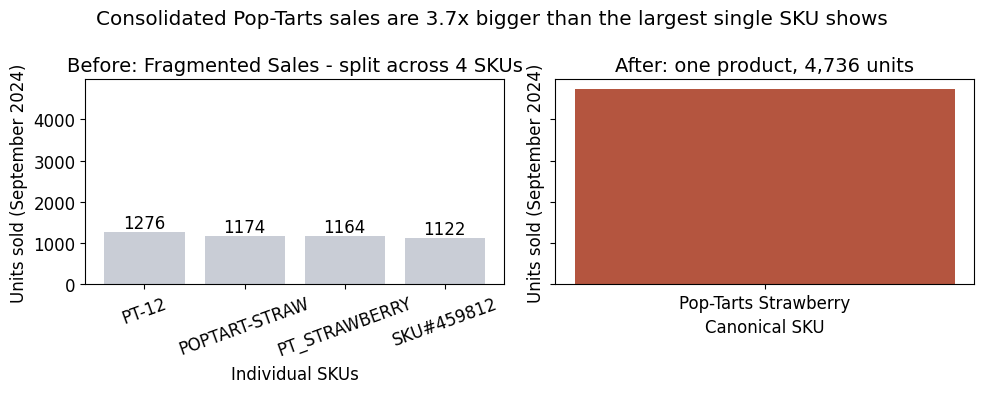

Largest single SKU: 1276 | Consolidated: 4736


In [27]:
import matplotlib.pyplot as plt

pop = poptarts.copy()
before = pop.groupby("sku")["quantity"].sum().sort_values(ascending=False) #sales before consolidation
after = before.sum()

#before consolidation
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].bar(before.index, before.values, color="#c9cdd6")
axes[0].set_title("Before: Fragmented Sales - split across 4 SKUs")
axes[0].set_ylabel("Units sold (September 2024)")
axes[0].set_xlabel("Individual SKUs")
axes[0].tick_params(axis="x", rotation=20)

#adding unit counts above the individual sku values
for i, value in enumerate(before.values):
  axes[0].text(i,value,str(value), ha="center",va="bottom")


#after consolidation
axes[1].bar([largest], [after], color="#b4553f")
axes[1].set_title(f"After: one product, {after:,.0f} units")
axes[1].set_ylabel("Units sold (September 2024)")
axes[1].set_xlabel("Canonical SKU")
fig.suptitle(f"Consolidated Pop-Tarts sales are {after / before.max():.1f}x bigger than the largest single SKU shows")
plt.tight_layout()
plt.show()

print("Largest single SKU:", before.max(), "| Consolidated:", after)
assert before.sum() == after

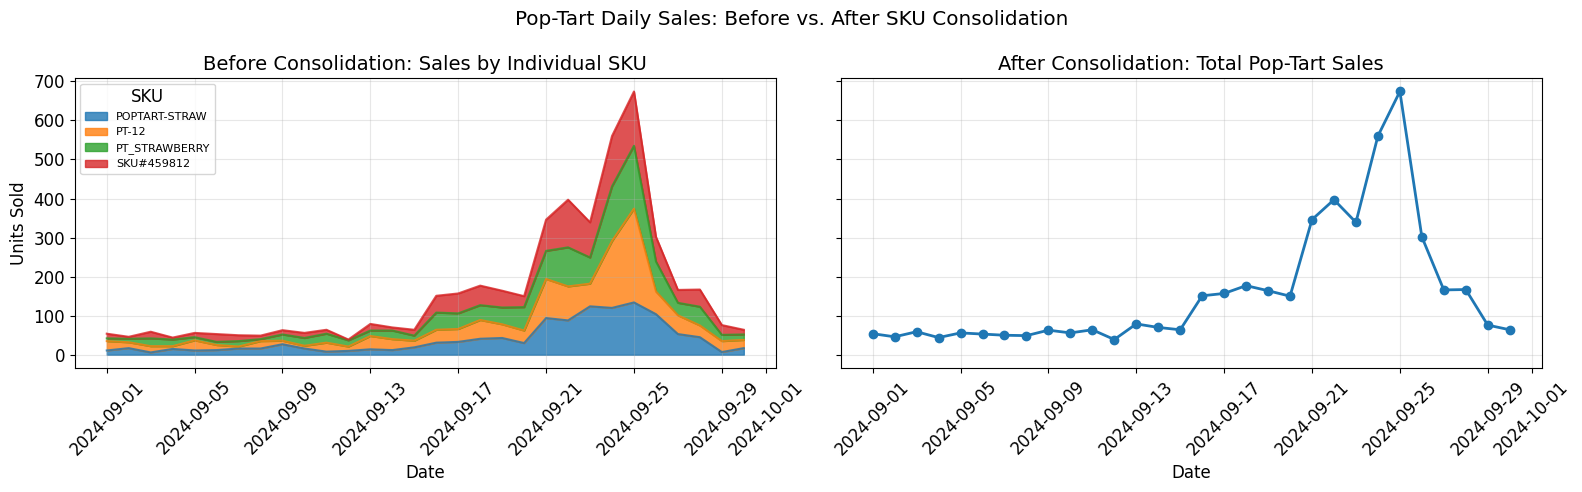

In [28]:
import matplotlib.pyplot as plt

# Organize daily sales by individual SKU
before = poptarts.pivot_table(
    index='date',
    columns='sku',
    values='quantity',
    aggfunc='sum',
    fill_value=0
)

# Create side-by-side graphs
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# Before consolidation: stacked area chart
before.plot(
    kind='area',
    stacked=True,
    ax=axes[0],
    alpha=0.8
)

axes[0].set_title('Before Consolidation: Sales by Individual SKU')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Units Sold')
axes[0].legend(title='SKU', fontsize=8)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# After consolidation: total daily sales
axes[1].plot(
    daily_sales['date'],
    daily_sales['total_poptarts_sold'],
    marker='o',
    linewidth=2
)

axes[1].set_title('After Consolidation: Total Pop-Tart Sales')
axes[1].set_xlabel('Date')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Pop-Tart Daily Sales: Before vs. After SKU Consolidation')
plt.tight_layout()
plt.show()

**Markdown Explanation of What We Did**
First we grouped SKUs by looking at where product names overlapped but were appearing with different SKU values. From here we combined them under one SKU for each product type, the canonical SKU. This is important because it helps provide better data and analysis since we can see the true sales of Strawberry Poptarts instead of 4 separate products with 4 different SKUs that make the numbers seem much lower than they should. By combining SKUs, we can see the true inventory and sales impact of each product. This continued for the second part where we were able to better visualize the daily sales volume for strawberry poptarts because now we could see the total sold versus the fragmented SKUs which caused underestimates of the poptarts popularity.

**Markdown Explanation of Visuals:** The first visual created helps understand the sales and what they look like when they are presented fragmented or consolidated. As one can see by the assertion, the values are the same of both graphs, but adding the SKUs together because they represent the same well-selling product tells a much different story than 4 mediocre-selling products. The second visual shows this again but this time instead of total sales in September, it breaks sales into daily sales by SKU which is especially helpful in relevance to the storm and inventory connection. If we see peaks in the data at certain days that align with the storm, we could then tell if something is going on. The first daily sales chart is a stacked area chart which illustrates how each of the SKUs build on each other to be the total large number of daily sales we see of strawberry poptarts consolidated SKU.

**After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?**

**Answer:** After standardizing all the Pop-Tart SKU variants into a single product, we can see that the true daily sales volume for Strawberry Poptarts is very large. We did this by taking 45 distinct SKUs and turning them into 20 canonical SKUs or more specifically for Strawberry Pop-Tarts, taking 4 distinct SKUs and turning it into 1 consolidated canonical SKU. Looking at the September daily poptart sales volume table, sales increased a lot towards the end of the month which coincides with the days leading up to the storm. From September 21st when people first started stocking up until September 26th when the hurricane hit, over 300 units were sold a day, with the two peak days of September 24 and 25, totaling 1234 sales together.
Without consolidating, we would have never been able to get this insight. With the fragmented SKUs, it seems like we have 4 average performing products for the month of September, but when you add them into one consolidated SKU, we notice an exceptional product that is flying off the shelves. For example, looking at the first graph of fragmented versus consolidated SKUs, the consolidated September Strawberry Pop Tart sales are 3.7 times larger than the largest single, fragmented SKU. This highlights how analyzing each SKU separately for the same product can greatly distort findings and hide significance.


As for business decisions, they vary depending what approach one takes to analysis. With the fragmented view, Walmart might make a business decision to prioritize other products that aren't poptarts because these just seem to be 4 normal selling goods, therefore losing potential profit since the pop tarts were actually a high seller. However, with a consolidated SKU, Walmart can easily recognize the high demand and therefore make better decisions like to restock the shelves. This would especially be important during major events like the hurricane when last minute transportation of goods could be limited.

**Walmart Next Steps:** Using the consolidated SKU, Walmart should work towards more forecasting and inventory preparation. Seeing both the large amount of sales in Strawberry pop-tarts, as well as the increased daily sales during storm, Walmart should think about investing in this product and shelving it as much as possible. However, it would also be beneficial for them to look at other products or other time periods to confirm that Strawberry Pop-Tarts really are the high-performing outlier.

## **Question 3:**

,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean
orders,1.000000,-0.249757,0.391469,-0.262693
precipitation_sum,-0.249757,1.000000,-0.041890,0.238997
windspeed_10m_max,0.391469,-0.041890,1.000000,-0.701757
surface_pressure_mean,-0.262693,0.238997,-0.701757,1.000000


,date,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
20,2024-09-21,1313,0.4,19.9,1008.025000,open-meteo
21,2024-09-22,1367,2.2,17.9,1008.137500,open-meteo
22,2024-09-23,1374,1.3,16.6,1008.700000,open-meteo
23,2024-09-24,1968,0.3,17.7,1009.008333,open-meteo
24,2024-09-25,2007,6.4,27.2,1007.233333,open-meteo
25,2024-09-26,1139,15.2,48.8,999.675000,open-meteo
26,2024-09-27,851,2.5,40.1,1002.237500,open-meteo
27,2024-09-28,879,18.0,19.8,1007.766667,open-meteo


,lag,correlation,n_pairs
0,-14,-0.179280,16
1,-13,-0.273784,17
2,-12,-0.200816,18
3,-11,0.107861,19
4,-10,0.480341,20
5,-9,0.157871,21
6,-8,0.056510,22
7,-7,0.056579,23
8,-6,0.135153,24
9,-5,0.293070,25


Strongest lag: -2
Correlation: 0.823 on 28 pairs


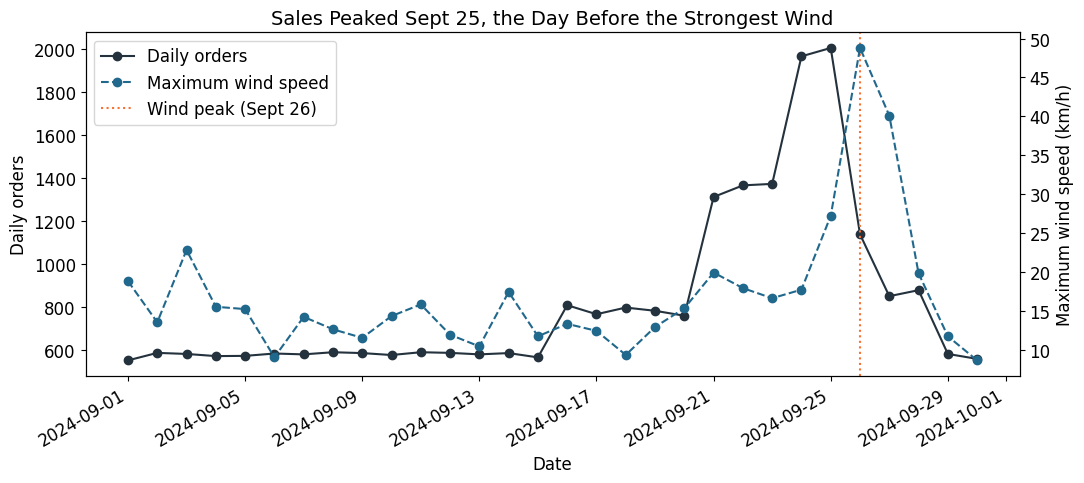

,precipitation_corr,wind_corr,pressure_corr
category_clean,,,
Alcohol,-0.255,0.372,-0.220
Baby,-0.304,0.214,-0.162
Breakfast,-0.239,0.403,-0.278
Electronics,-0.242,0.367,-0.229
Emergency,-0.248,0.424,-0.301
Entertainment,-0.214,0.426,-0.293
Grocery,-0.278,0.296,-0.172
Health,-0.253,0.365,-0.258
Household,-0.224,0.393,-0.252


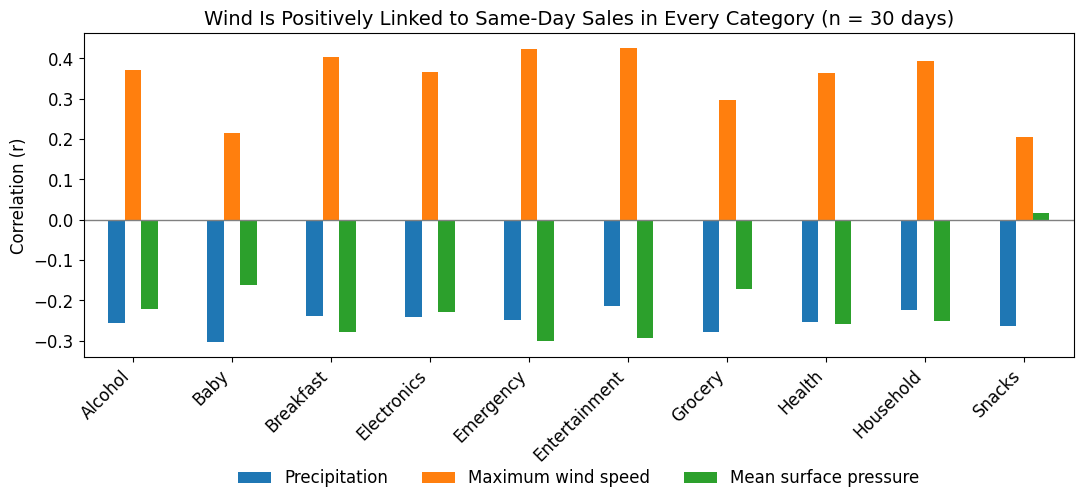

In [29]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14})

display(sales_weather[["orders", "precipitation_sum", "windspeed_10m_max", "surface_pressure_mean"]].corr())
display(sales_weather[(sales_weather["date"] >= "2024-09-21") & (sales_weather["date"] <= "2024-09-28")])

lag_results = []
for lag in range(-14, 15):
    shifted_wind = sales_weather["windspeed_10m_max"].shift(lag)
    valid_pairs = sales_weather["orders"].notna() & shifted_wind.notna()
    corr = sales_weather.loc[valid_pairs, "orders"].corr(shifted_wind[valid_pairs])
    lag_results.append({"lag": lag, "correlation": corr, "n_pairs": valid_pairs.sum()})
lag_results = pd.DataFrame(lag_results)
display(lag_results)

best_lag = lag_results.loc[lag_results["correlation"].abs().idxmax()]
print("Strongest lag:", int(best_lag["lag"]))
print("Correlation:", round(best_lag["correlation"], 3), "on", int(best_lag["n_pairs"]), "pairs")

fig, ax1 = plt.subplots(figsize=(11, 5))
sales_line = ax1.plot(sales_weather["date"], sales_weather["orders"], marker="o", color="#24323E", label="Daily orders")
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily orders")
ax2 = ax1.twinx()
wind_line = ax2.plot(sales_weather["date"], sales_weather["windspeed_10m_max"], marker="o", linestyle="--",
                     color="#21688D", label="Maximum wind speed")
ax2.set_ylabel("Maximum wind speed (km/h)")
wind_peak = ax1.axvline(pd.Timestamp("2024-09-26"), color="#F67132", linestyle=":", label="Wind peak (Sept 26)")
lines = sales_line + wind_line + [wind_peak]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")
plt.title("Sales Peaked Sept 25, the Day Before the Strongest Wind")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

category_map = {
    "emergency": "Emergency", "emergency supplies": "Emergency",
    "groceries": "Grocery", "grocery": "Grocery",
    "electronics": "Electronics",
    "entertainment": "Entertainment", "games & entertainment": "Entertainment",
    "household": "Household", "household essentials": "Household",
    "baby": "Baby", "baby products": "Baby",
    "breakfast": "Breakfast", "breakfast foods": "Breakfast",
    "alcohol": "Alcohol", "alcoholic beverages": "Alcohol",
    "snacks": "Snacks",
    "health": "Health", "health & wellness": "Health",
}
sales_prepared["category_clean"] = sales_prepared["category"].str.strip().str.lower().map(category_map)

daily_category_sales = (
    sales_prepared.dropna(subset=["date", "category_clean"])
    .groupby(["date", "category_clean"]).size()
    .reset_index(name="orders")
)
category_weather = daily_category_sales.merge(weather_live, on="date", how="left")

category_correlations = (
    category_weather.groupby("category_clean")
    .apply(lambda x: pd.Series({
        "precipitation_corr": x["orders"].corr(x["precipitation_sum"]),
        "wind_corr": x["orders"].corr(x["windspeed_10m_max"]),
        "pressure_corr": x["orders"].corr(x["surface_pressure_mean"]),
    }), include_groups=False)
    .round(3)
)
display(category_correlations)

ax = category_correlations.rename(columns={
    "precipitation_corr": "Precipitation",
    "wind_corr": "Maximum wind speed",
    "pressure_corr": "Mean surface pressure",
}).plot(kind="bar", figsize=(11, 5.5))
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Wind Is Positively Linked to Same-Day Sales in Every Category (n = 30 days)")
ax.set_xlabel("")
ax.set_ylabel("Correlation (r)")
plt.xticks(rotation=45, ha="right")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**Markdown Explanation of What We Did**

The order count per day (all stores with duplicates removed) was linked to the weather of Orlando per day using the Open-Meteo API via a left join on dates, so no sales day was dropped. The correlation was computed between the orders and wind speed, precipitation, and surface pressure for total orders as well as the 10 different categories on the same day. In order to investigate a lag effect, wind speed was lagged by -14 to +14 days, recording the correlation and number of overlapping days for each shift.

**Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?**

**Answer:**  On the same day, there was a moderate positive correlation between maximum wind speed and sales (r = 0.391, n = 30), but there was a weak negative correlation between sales and precipitation (r = -0.250, n = 30) and mean surface pressure (r = -0.263, n = 30). There was a high correlation between low pressure and high winds (r = -0.702). The category level correlations revealed the same trend for all categories, with positive wind correlations ranging from 0.206 (Snacks) to 0.426 (Entertainment). The correlation coefficient showed the highest value with lag -2 days (r = 0.823, n = 28 pairs), which indicates that increased sales occurred two days before increased wind speeds. The peak of sales was observed from September 24 to 25, with 1,968 and 2,007 orders respectively, whereas the peak of wind speed was recorded on September 26, which amounted to 48.8 km/h, i.e., the day when the landfall occurred. Since it’s only one month and one weather location, this result should be considered as just a time relationship.

## **Question 4:**

In [30]:
# Part 4.1 Create a dataframe with each store's surge_multiple and total transactions
#Calculate daily sales by store
daily_store = (
    sales_clean.groupby(["date", "store_id"])["quantity"]
    .sum()
    .reset_index()
)

# Separate baseline and surge periods
baseline_store = daily_store[
    (daily_store["date"] >= "2024-09-08") &
    (daily_store["date"] <= "2024-09-15")
]

surge_store = daily_store[
    (daily_store["date"] >= "2024-09-19") &
    (daily_store["date"] <= "2024-09-25")
]

# Calculate average daily sales for each store
baseline_avg = baseline_store.groupby("store_id")["quantity"].mean()
surge_avg = surge_store.groupby("store_id")["quantity"].mean()

# Calculate surge multiple
surge_multiple = surge_avg / baseline_avg
percent_increase = (surge_multiple - 1) * 100

# Create store results
store_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "surge_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_increase": percent_increase
}).sort_values("percent_increase", ascending=False)

store_results = store_results.reset_index()

# Calculate total transactions/quantity for each store
total_store_sales = (
    sales_clean.groupby("store_id")["quantity"]
    .sum()
    .reset_index(name="total_transactions")
)

# Join store_results with total_transactions
store_results = store_results.merge(
    total_store_sales,
    on="store_id",
    how="left"
)

In [31]:
#4.2 Join surge multiple and store location dataframes from 4.1 and 4.2
#5 JOIN store results with store locations and total transactions
store_results = store_results.merge(
    stores_clean[["store_id", "latitude", "longitude", "region"]],
    on="store_id",
    how="left"
)

# Update the store's coordinates
store_results.loc[store_results["store_id"] == "FL-619", "latitude"] = 30.4383
store_results.loc[store_results["store_id"] == "FL-619", "longitude"] = -84.2807

In [32]:
#4.3 add distance from storm landfall to 4.3 dataframe

import numpy as np

# Set reference coordinates for storm landfall
reference_lat = 30.0
reference_long = -83.7

# Haversine distance function
def calculate_distance(lat1, lon1, lat2, lon2):
    earth_radius = 3958.8  # Earth radius in miles

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return earth_radius * c


# Calculate distance for every store
store_results["miles_from_landfall"] = calculate_distance(
    reference_lat,
    reference_long,
    store_results["latitude"].astype(float),
    store_results["longitude"].astype(float)
)

# Display results
display(store_results.round(2))

,store_id,baseline_avg,surge_avg,surge_multiple,percent_increase,total_transactions,latitude,longitude,region,miles_from_landfall
0,FL-330,83.38,235.14,2.82,182.03,4195,25.76,-80.19,South,362.80
1,FL-619,80.75,222.43,2.75,175.45,4003,30.44,-84.28,Panhandle,46.03
2,FL-105,90.88,231.29,2.55,154.51,4152,27.95,-82.46,West,160.29
3,FL-710,90.25,226.43,2.51,150.89,4119,30.42,-87.22,Panhandle,211.99
4,FL-445,93.62,231.43,2.47,147.19,4253,27.77,-82.64,West,167.04
5,FL-412,89.62,221.43,2.47,147.06,4077,30.33,-81.66,North,124.26
6,FL-302,97.62,239.29,2.45,145.11,4257,28.04,-81.95,Central,171.84
7,FL-287,89.50,218.71,2.44,144.37,4057,28.29,-81.41,Central,181.83
8,FL-156,95.25,228.57,2.40,139.97,4187,29.21,-81.02,East,169.82
9,FL-078,93.00,217.00,2.33,133.33,4027,29.65,-82.32,North,85.87


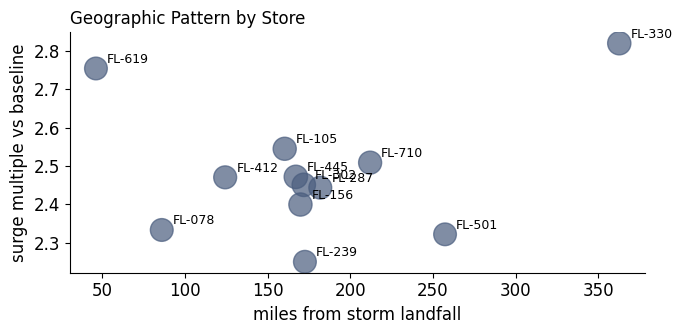

In [33]:
#4.4 Create scatter plot showing the geographic pattern of surge multiple by individual store
by_store = store_results[["store_id","surge_multiple","miles_from_landfall","total_transactions"]]

# Create scatter plot
fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['total_transactions'] / 15
ax.scatter(by_store['miles_from_landfall'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_landfall, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Geographic Pattern by Store',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm landfall')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

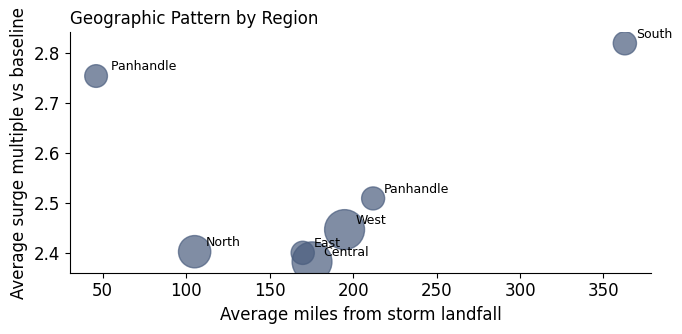

In [34]:
#4.5 Create scatter plot showing the geographic pattern of surge multiple by region
# Group stores by region
by_region = (
    store_results.groupby("region")
    .agg(
        surge_multiple=("surge_multiple", "mean"),
        miles_from_landfall=("miles_from_landfall", "mean"),
        total_transactions=("total_transactions", "sum")
    )
    .reset_index()
)

# Create scatter plot
fig, ax = plt.subplots(figsize=(7, 3.5))

sizes = by_region["total_transactions"] / 15

ax.scatter(
    by_region["miles_from_landfall"],
    by_region["surge_multiple"],
    s=sizes,
    alpha=0.7,
    color="#4a5d7e"
)

# Label each region
for row in by_region.itertuples():
    ax.annotate(
        row.region,
        (row.miles_from_landfall, row.surge_multiple),
        textcoords="offset points",
        xytext=(8, 4),
        fontsize=9
    )

ax.set_title("Geographic Pattern by Region",
             loc="left", fontsize=12)
ax.set_xlabel("Average miles from storm landfall")
ax.set_ylabel("Average surge multiple vs baseline")

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

**Markdown Explanation of What We Did**

**Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.**

## **Question 5:**

In [35]:
import pandas as pd
import sqlite3
import requests

base = "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/main/notebooks/walmart-hurricane-project/data/"

# download the database file so sqlite3 can open it
r = requests.get(base + "inventory_and_sales.db", timeout=30)
r.raise_for_status()
with open("inventory_and_sales.db", "wb") as f:
    f.write(r.content)

conn = sqlite3.connect("inventory_and_sales.db")
db_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", conn)
inventory = pd.read_sql_query("SELECT * FROM inventory_levels", conn)

db_sales["date"] = pd.to_datetime(db_sales["date"], format="mixed")
inventory["date"] = pd.to_datetime(inventory["date"], format="mixed")

tx = pd.read_csv(base + "walmart_transactions.csv").drop_duplicates()
tx["date"] = pd.to_datetime(tx["timestamp"], format="mixed", errors="coerce").dt.normalize()
tx["quantity"] = pd.to_numeric(tx["quantity"], errors="coerce")

# what is actually inside "Entertainment"?
ent = tx[tx["category"].str.strip().str.lower().isin(["entertainment", "games & entertainment"])]
print(ent.groupby(["sku", "product_name"]).size())

# consolidate the SKUs into the two real products
game_map = {
    "BG-MONO": "Board games", "GAME-MONO": "Board games", "MONOPOLY-01": "Board games",
    "CARDS-01": "Playing cards", "PLAYCARD-STD": "Playing cards",
}
tx["game_product"] = tx["sku"].map(game_map)
inventory["game_product"] = inventory["sku"].map(game_map)

print("\nSKUs per product:")
print(tx.dropna(subset=["game_product"]).groupby("game_product")["sku"].unique())

sku           product_name          
BG-MONO       Board Game - Monopoly     133
              MONOPOLY                  135
              Monopoly Board Game       164
CARDS-01      PLAYING CARDS             191
              Playing Cards             203
              Standard Playing Cards    193
GAME-MONO     Board Game - Monopoly     171
              MONOPOLY                  152
              Monopoly Board Game       143
MONOPOLY-01   Board Game - Monopoly     155
              MONOPOLY                  144
              Monopoly Board Game       142
PLAYCARD-STD  PLAYING CARDS             201
              Playing Cards             201
              Standard Playing Cards    210
dtype: int64

SKUs per product:
game_product
Board games      [BG-MONO, MONOPOLY-01, GAME-MONO]
Playing cards             [CARDS-01, PLAYCARD-STD]
Name: sku, dtype: object


In [36]:
baseline = ("2024-09-08", "2024-09-15")
surge = ("2024-09-19", "2024-09-25")

daily_cat = db_sales.groupby(["date", "category"])["total_units"].sum().unstack()

base_avg = daily_cat.loc[baseline[0]:baseline[1]].mean()
surge_avg = daily_cat.loc[surge[0]:surge[1]].mean()
peak_day = daily_cat.loc[surge[0]:surge[1]].idxmax()
peak_val = daily_cat.loc[surge[0]:surge[1]].max()

check = pd.DataFrame({
    "week_increase_%": ((surge_avg / base_avg - 1) * 100).round(1),
    "peak_day": peak_day.dt.strftime("%b %d"),
    "peak_day_increase_%": ((peak_val / base_avg - 1) * 100).round(1),
}).sort_values("week_increase_%", ascending=False)

check

,week_increase_%,peak_day,peak_day_increase_%
category,,,
Breakfast,229.5,Sep 25,455.4
Emergency,182.6,Sep 25,311.7
Entertainment,135.3,Sep 24,256.5
Health,117.2,Sep 24,217.5
Alcohol,107.5,Sep 24,191.2
Electronics,94.7,Sep 25,202.2
Household,93.7,Sep 24,180.8
Baby,58.6,Sep 25,133.6
Grocery,55.2,Sep 24,106.3


In [37]:
games = tx[tx["game_product"].notna() & (tx["quantity"] > 0)]
daily_games = (
    games.groupby(["date", "game_product"])["quantity"].sum()
    .unstack(fill_value=0)
)
daily_games["Entertainment total"] = daily_games.sum(axis=1)

game_base = daily_games.loc[baseline[0]:baseline[1]].mean()
game_surge = daily_games.loc[surge[0]:surge[1]].mean()

game_check = pd.DataFrame({
    "baseline_per_day": game_base.round(1),
    "surge_per_day": game_surge.round(1),
    "week_increase_%": ((game_surge / game_base - 1) * 100).round(1),
})
game_check

,baseline_per_day,surge_per_day,week_increase_%
game_product,,,
Board games,42.9,111.4,159.9
Playing cards,59.1,117.1,98.1
Entertainment total,102.0,228.6,124.1


In [38]:
# does inventory drop when sales go up? (real sales should use up stock)
inventory["product"] = inventory["game_product"]
inventory.loc[inventory["sku"].isin(["PT-12", "POPTART-STRAW", "PT_STRAWBERRY", "SKU#459812"]), "product"] = "Pop-Tarts (for comparison)"

stock = (
    inventory.dropna(subset=["product"])
    .groupby(["date", "product"])["units_on_hand"].mean()
    .unstack()
)

stock_check = pd.DataFrame({
    "mid_Sept_stock (Sept 13-18)": stock.loc["2024-09-13":"2024-09-18"].mean().round(0),
    "pre_landfall_stock (Sept 22-25)": stock.loc["2024-09-22":"2024-09-25"].mean().round(0),
})
display(stock_check)

# SKUs in inventory that never show up in sales
orphan_skus = sorted(set(inventory["sku"]) - set(tx["sku"]))
print("Inventory SKUs with no sales records:", orphan_skus)

,mid_Sept_stock (Sept 13-18),pre_landfall_stock (Sept 22-25)
product,,
Board games,128.0,36.0
Playing cards,127.0,27.0
Pop-Tarts (for comparison),123.0,37.0


Inventory SKUs with no sales records: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']


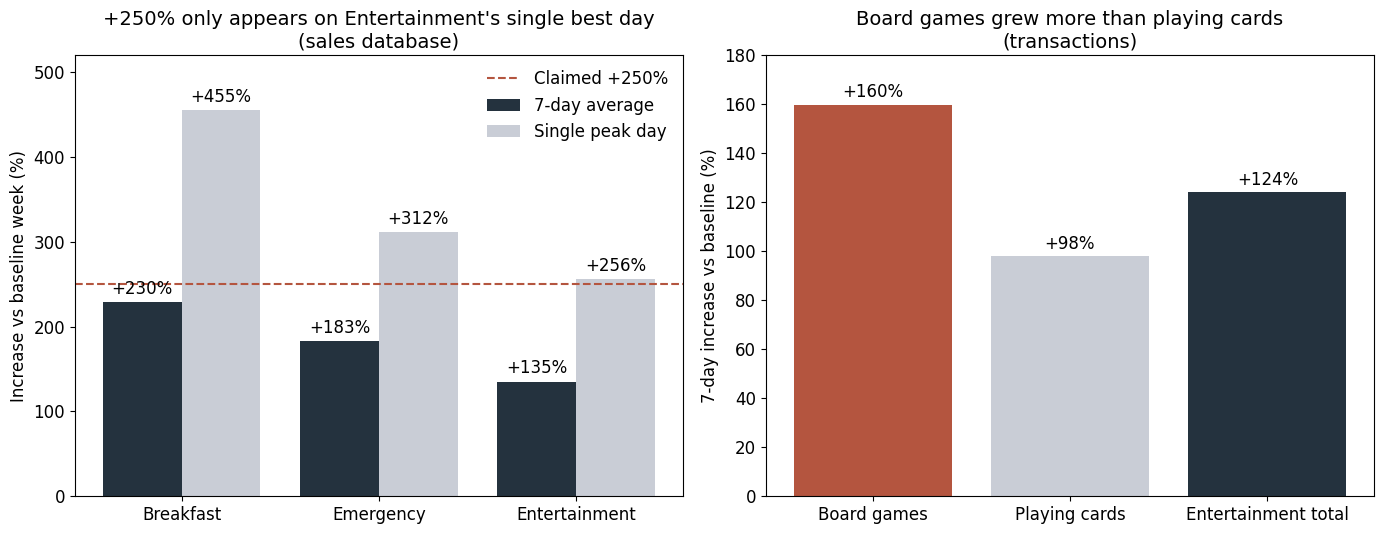

In [39]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# left: the +250% only shows up on the single peak day
top = check.loc[["Breakfast", "Emergency", "Entertainment"]]
x = range(len(top))
week_bars = ax1.bar([i - 0.2 for i in x], top["week_increase_%"], width=0.4, label="7-day average", color="#24323E")
peak_bars = ax1.bar([i + 0.2 for i in x], top["peak_day_increase_%"], width=0.4, label="Single peak day", color="#c9cdd6")
ax1.bar_label(week_bars, labels=[f"+{v:.0f}%" for v in top["week_increase_%"]], padding=3)
ax1.bar_label(peak_bars, labels=[f"+{v:.0f}%" for v in top["peak_day_increase_%"]], padding=3)
ax1.axhline(250, color="#b4553f", linestyle="--", label="Claimed +250%")
ax1.set_xticks(list(x))
ax1.set_xticklabels(top.index)
ax1.set_ylim(0, 520)
ax1.set_ylabel("Increase vs baseline week (%)")
ax1.set_title("+250% only appears on Entertainment's single best day\n(sales database)")
ax1.legend(frameon=False, loc="upper right")

# right: Entertainment mixes two products that grew differently
parts = game_check.loc[["Board games", "Playing cards", "Entertainment total"], "week_increase_%"]
ax2.bar(parts.index, parts.values, color=["#b4553f", "#c9cdd6", "#24323E"])
for i, v in enumerate(parts.values):
    ax2.text(i, v + 3, f"+{v:.0f}%", ha="center")
ax2.set_ylim(0, 180)
ax2.set_ylabel("7-day increase vs baseline (%)")
ax2.set_title("Board games grew more than playing cards\n(transactions)")

plt.tight_layout()
plt.show()

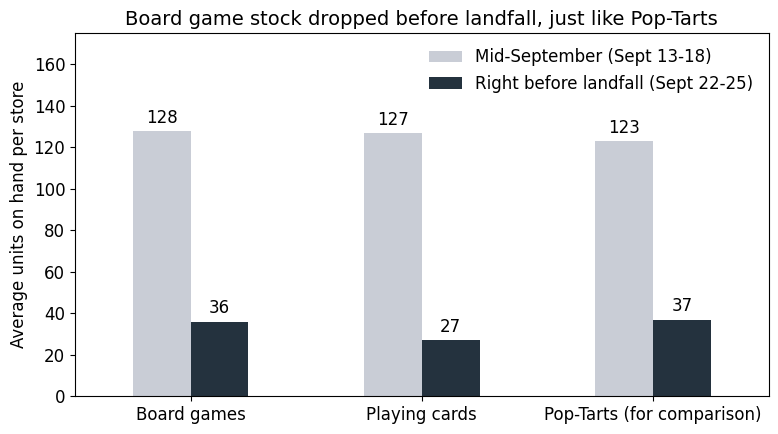

In [40]:
ax = stock_check.plot(kind="bar", figsize=(8, 4.5), color=["#c9cdd6", "#24323E"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_ylim(0, 175)
ax.set_ylabel("Average units on hand per store")
ax.set_xlabel("")
ax.set_title("Board game stock dropped before landfall, just like Pop-Tarts")
ax.legend(["Mid-September (Sept 13-18)", "Right before landfall (Sept 22-25)"],
          frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**Markdown Explanation of What We Did**

We imported the daily_sales_summary and inventory_levels tables from the SQLite database and the transactions file as well. First, we investigated what is present in the Entertainment category and found out there are just two items within: Monopoly (3 SKUs) and playing cards (2 SKUs); therefore, we grouped all these SKUs. Then we analyzed the seven-day period before the storm (Sept 19-25) vs. the baseline week (Sept 8-15) and the single peak day as well. Furthermore, we divided the Entertainment category into board games and playing cards, investigated if the store inventory decreased during the spike and investigated SKUs not present in sales but present in the inventory table.

**The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?**

**Answer:** The board game spike is a reality, but +250% is overstated. Entertainment only reached +256% on a single day (Sept 24). On average over 7 days before the storm, entertainment grew by +135%, which is lower compared to Breakfast (+230%) and Emergency Supplies (+183%). This category includes two products: board games increased by +160% while playing cards increased by +98%. The spike seems to be driven by real consumer demand and not by mistake since the board game stock fell from ~128 to 36 units per store before the storm, just like Pop-Tarts (123 to 37). 4 SKUs were found in the inventory that are never part of any sale (UNKNOWN-99, MISC-001, LEGACY-PT, OLD-BATT-50); however, there is no link between those and board games. Recommendation for Walmart: it is advised to stock more board games for the next storm, planning for about double normal sales instead of 3.5 times, but not taking truck space from Breakfast and Emergency Supplies, which increased more.

**Next steps:** (1) Prior to the next storm, stock about twice the usual amount of board games for the week before the storm’s landfall, reserving any extra truck capacity only after Breakfast and Emergency Supply SKUs have been filled. (2) It would be better to consolidate the Monopoly SKUs into one item and the Playing Card SKUs into one item, so each shows up as a single product in future reports. (3) Storm surges are to be counted in seven-day averages and not just peak days, and board games have to be considered separate from playing cards. (4) Check out the four SKUs not appearing in sales.


# Reflection Questions

## **Question 1: Data Quality Impact**
**Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?**

## **Question 2: ETL Trade-offs**
**You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?**

A decision we had to make was how to merge the weather data with the sales data. We chose a left join based on date because it kept all the sales days, even if there was no corresponding weather data. On the other hand, an inner join would only keep the days when there was a match on both sides. In our case, all 30 days matched, so we would have gotten the same result whichever method we chose. However, if there were one day missing from the weather data, the inner join would have silently omitted that day from the analysis. That would be critical if the missing day was September 26, the landfall day. We would have lost the most important day of the entire analysis, and the plot would appear completely normal.

Another decision we made was to request the weather data in Eastern time instead of the API's default UTC. There are 120 out of the 720 hours that fall on a different date in UTC. Therefore, the wind peak would appear on September 27 instead of September 26, shifting our lag result by a day.

## **Question 3: Pipeline Trust**
**The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?**

We agree with the CDO. Most of the issues we faced arose due to the data pipeline and not due to the calculations. Cleaning the data made it easy for us to calculate the correlation and surge multiples. The most vulnerable part of the data pipeline was the timestamp parser. We had a sales file with five different formats for dates, but with pandas, we could read just one without format="mixed". Therefore, out of 25,562 rows, we got date information on only 2,511. There were no errors at all, and our Q1 sales figure was roughly 10 times smaller. Breakfast continued to be the top category, which made it easy to forget about this issue. The other issue was SKU fragmentation, where the Pop-Tarts brand had been fragmented into 4 SKUs, and the largest SKU had understated the demand by 3.8 times. The live weather API produced slightly different results every time, causing some variations in the correlations (e.g., 0.375 versus 0.391). Overall, the important lesson that we learned from this exercise was the need to validate row counts after each step due to silent row drops.

## **Question 4: Business vs. Data**
**For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?**

We didn’t take the +250% at face value. It only happened on one day (Sept 24), so we used the 7-day average instead, which was +135%. It was still an actual growth since the inventory proved that the board games supply fell from 128 to 36 per store prior to the storm, meaning that people were purchasing them and it wasn’t a miscalculation. In terms of business risks, the board games take up truck space that could go to goods such as Breakfast and Emergency Supplies (230% and 183% growth). Therefore, it was advised that there should be a provision of double normal board games rather than 3.5 times the normal number, only after stocking the more essential goods. Over-stocking of board games would not affect much, but lack of water or batteries could make things worse. If given more time or data, we would have checked previous hurricanes and other stores to check if the same trend exists. It is currently based on one hurricane and one month’s experience.

## **Question 5: Team Collaboration**
**How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?**

Our team divided the work by first allowing each person to choose a section they wanted to work on, and then collaborating and helping each other later. We found this to be the best practice because by allowing people to choose which parts of the project they wanted to do, they were able to play to their strengths better. Additionally, the fact that we then after working a bit individually, came together to help each other, made our work cohesive and helped us fix any bugs in our code we may have struggled with. Despite our strong division of work, one thing we could work on better in the future is time management. Perhaps setting intermediate deadlines for us all to be finished with our work instead of going at our own paces because it sometimes made it difficult to work on questions where data or cleaning overlapped with another part. However, overall, we think we were a very strong team. Noor did an excellent job of debugging, when people ran into issues she was able to help them so we could keep moving forward. Aubin did a great job of communicating - between going to office hours, using Discord, or asking the teacher, she made sure we clarified our understanding of what was being asked of each of us. Something Angela did well was be very repsonsive. She drove a lot of the discussion in our group meetings and group chat, pushing us to get our work done. Nico's best skill was critical thinking - when he got confused he would take the time to think of our project in terms of the real world to provide better insights and therefore better analysis.